In [30]:
import time
from collections import deque
import matplotlib.pyplot as plt

In [31]:
maze = [
    [0, 0, 1, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 1, 0, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
    [1, 1, 1, 0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 0, 1, 1, 1, 1, 1, 0],
    [0, 0, 1, 0, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
]

start = (0, 0)
goal = (9, 9)

rows = len(maze)
cols = len(maze[0])

print("Start:", start)
print("Goal:", goal)

Start: (0, 0)
Goal: (9, 9)


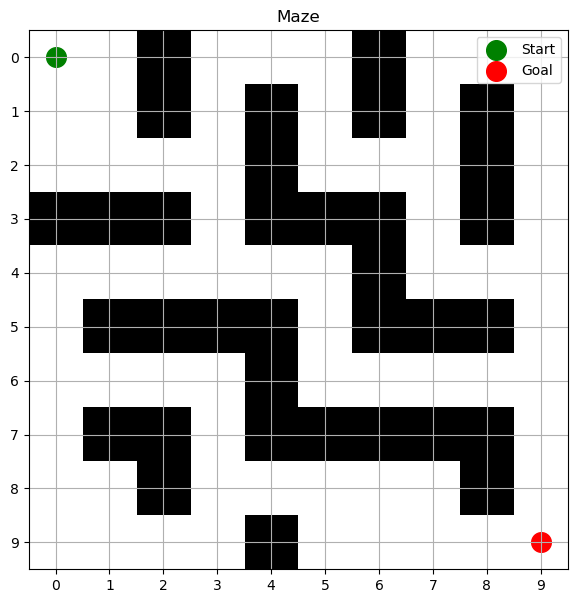

In [32]:
def display_maze(maze, start, goal):
    plt.figure(figsize=(7, 7))
    
    plt.imshow(maze, cmap="binary")
    
    plt.scatter(
        start[1], start[0],
        color="green",
        s=200,
        label="Start"
    )
    
    plt.scatter(
        goal[1], goal[0],
        color="red",
        s=200,
        label="Goal"
    )
    
    plt.xticks(range(len(maze[0])))
    plt.yticks(range(len(maze)))
    plt.grid(True)
    plt.legend()
    plt.title("Maze")
    plt.show()

display_maze(maze, start, goal)

In [33]:
directions = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1)     # Right
]

def get_neighbors(position):
    row, col = position
    
    neighbors = []
    
    for dr, dc in directions:
        new_row = row + dr
        new_col = col + dc
        
        if 0 <= new_row < rows and 0 <= new_col < cols:
            
            if maze[new_row][new_col] == 0:
                neighbors.append((new_row, new_col))
    
    return neighbors

In [34]:
def bfs(maze, start, goal):
    
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    nodes_explored = 0
    
    while queue:
        
        current = queue.popleft()
        nodes_explored += 1
        
        if current == goal:
            break
        
        for neighbor in get_neighbors(current):
            
            if neighbor not in visited:
                
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)
    
    if goal not in parent:
        return None, nodes_explored
    
    path = []
    current = goal
    
    while current is not None:
        path.append(current)
        current = parent[current]
    
    path.reverse()
    
    return path, nodes_explored

In [35]:
def dfs(maze, start, goal):
    
    stack = [start]
    visited = {start}
    parent = {start: None}
    nodes_explored = 0
    
    while stack:
        
        current = stack.pop()
        nodes_explored += 1
        
        if current == goal:
            break
        
        for neighbor in get_neighbors(current):
            
            if neighbor not in visited:
                
                visited.add(neighbor)
                parent[neighbor] = current
                stack.append(neighbor)
    
    if goal not in parent:
        return None, nodes_explored
    
    path = []
    current = goal
    
    while current is not None:
        path.append(current)
        current = parent[current]
    
    path.reverse()
    
    return path, nodes_explored

In [36]:
start_time = time.perf_counter()

bfs_path, bfs_nodes = bfs(maze, start, goal)

bfs_time = time.perf_counter() - start_time

if bfs_path:
    print("BFS Path:")
    print(bfs_path)
    print("\nBFS Path Length:", len(bfs_path) - 1)
    print("BFS Nodes Explored:", bfs_nodes)
    print("BFS Execution Time:", bfs_time, "seconds")
else:
    print("No path found using BFS.")

BFS Path:
[(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (3, 3), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (6, 6), (6, 7), (6, 8), (6, 9), (7, 9), (8, 9), (9, 9)]

BFS Path Length: 18
BFS Nodes Explored: 58
BFS Execution Time: 0.00016229999982897425 seconds


In [37]:
start_time = time.perf_counter()

dfs_path, dfs_nodes = dfs(maze, start, goal)

dfs_time = time.perf_counter() - start_time

if dfs_path:
    print("DFS Path:")
    print(dfs_path)
    print("\nDFS Path Length:", len(dfs_path) - 1)
    print("DFS Nodes Explored:", dfs_nodes)
    print("DFS Execution Time:", dfs_time, "seconds")
else:
    print("No path found using DFS.")

DFS Path:
[(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (3, 3), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (6, 6), (6, 7), (6, 8), (6, 9), (7, 9), (8, 9), (9, 9)]

DFS Path Length: 18
DFS Nodes Explored: 19
DFS Execution Time: 0.00015270000039890874 seconds


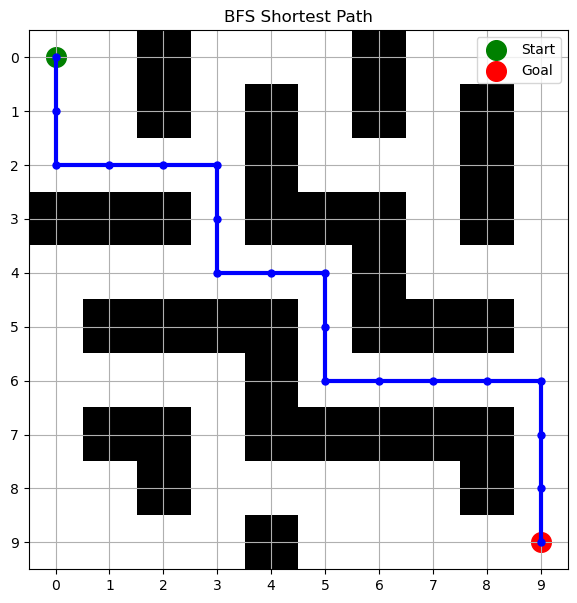

In [38]:
def visualize_path(maze, path, start, goal, title):
    
    plt.figure(figsize=(7, 7))
    
    plt.imshow(maze, cmap="binary")
    
    if path:
        path_rows = [p[0] for p in path]
        path_cols = [p[1] for p in path]
        
        plt.plot(
            path_cols,
            path_rows,
            color="blue",
            linewidth=3,
            marker="o",
            markersize=5
        )
    
    plt.scatter(
        start[1],
        start[0],
        color="green",
        s=200,
        label="Start"
    )
    
    plt.scatter(
        goal[1],
        goal[0],
        color="red",
        s=200,
        label="Goal"
    )
    
    plt.xticks(range(len(maze[0])))
    plt.yticks(range(len(maze)))
    plt.grid(True)
    plt.legend()
    plt.title(title)
    plt.show()


visualize_path(
    maze,
    bfs_path,
    start,
    goal,
    "BFS Shortest Path"
)

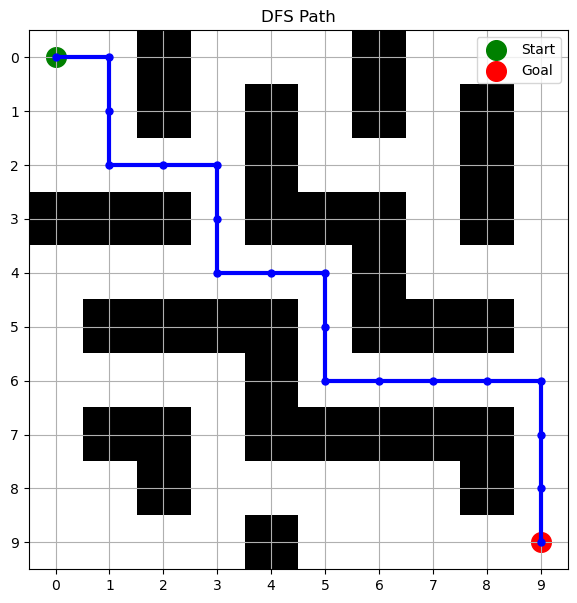

In [39]:
visualize_path(
    maze,
    dfs_path,
    start,
    goal,
    "DFS Path"
)

In [40]:
bfs_path_length = len(bfs_path) - 1 if bfs_path else None
dfs_path_length = len(dfs_path) - 1 if dfs_path else None

print("=" * 60)
print("              BFS vs DFS COMPARISON")
print("=" * 60)

print(f"{'Parameter':<25} {'BFS':<15} {'DFS':<15}")
print("-" * 60)

print(f"{'Path Length':<25} {bfs_path_length:<15} {dfs_path_length:<15}")
print(f"{'Nodes Explored':<25} {bfs_nodes:<15} {dfs_nodes:<15}")
print(f"{'Execution Time (sec)':<25} {bfs_time:<15.8f} {dfs_time:<15.8f}")

print("=" * 60)

              BFS vs DFS COMPARISON
Parameter                 BFS             DFS            
------------------------------------------------------------
Path Length               18              18             
Nodes Explored            58              19             
Execution Time (sec)      0.00016230      0.00015270     


In [41]:
print("\nRESULT ANALYSIS")
print("-" * 40)

if bfs_path_length < dfs_path_length:
    print("BFS found a shorter path than DFS.")
elif bfs_path_length > dfs_path_length:
    print("DFS found a shorter path than BFS.")
else:
    print("BFS and DFS found paths of the same length.")

if bfs_nodes < dfs_nodes:
    print("BFS explored fewer nodes.")
elif bfs_nodes > dfs_nodes:
    print("DFS explored fewer nodes.")
else:
    print("BFS and DFS explored the same number of nodes.")

if bfs_time < dfs_time:
    print("BFS executed faster.")
elif bfs_time > dfs_time:
    print("DFS executed faster.")
else:
    print("BFS and DFS had approximately the same execution time.")


RESULT ANALYSIS
----------------------------------------
BFS and DFS found paths of the same length.
DFS explored fewer nodes.
DFS executed faster.


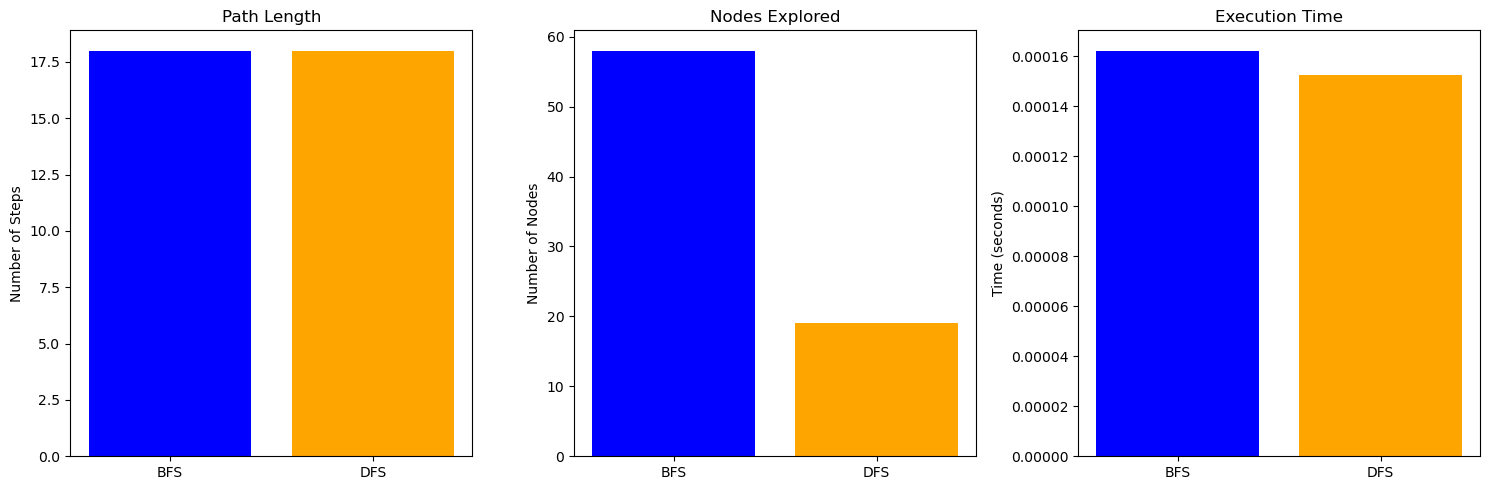

In [42]:
algorithms = ["BFS", "DFS"]

path_lengths = [bfs_path_length, dfs_path_length]
nodes_explored = [bfs_nodes, dfs_nodes]
execution_times = [bfs_time, dfs_time]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].bar(
    algorithms,
    path_lengths,
    color=["blue", "orange"]
)
axes[0].set_title("Path Length")
axes[0].set_ylabel("Number of Steps")

axes[1].bar(
    algorithms,
    nodes_explored,
    color=["blue", "orange"]
)
axes[1].set_title("Nodes Explored")
axes[1].set_ylabel("Number of Nodes")

axes[2].bar(
    algorithms,
    execution_times,
    color=["blue", "orange"]
)
axes[2].set_title("Execution Time")
axes[2].set_ylabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [ ]:
from collections import deque
import time

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': ['G'],
    'G': []
}

# Breadth First Search
def bfs(start, goal):
    q = deque([start])
    visited = []

    while q:
        n = q.popleft()

        if n == goal:
            return visited

        if n not in visited:
            visited.append(n)
            q.extend(graph[n])

    return visited

print(bfs('A', 'G'))


# Depth First Search
def dfs(start, goal):
    stack = [start]
    visited = []

    while stack:
        n = stack.pop()

        if n == goal:
            return visited

        if n not in visited:
            visited.append(n)
            stack.extend(graph[n])

    return visited

print(dfs('A', 'G'))


# Compare BFS and DFS
for search in [bfs, dfs]:
    start_time = time.time()
    path, nodes = search('A', 'G')
    end_time = time.time()

    print(search.__name__.upper())
    print("Path:", path)
    print("Path length:", len(path) - 1 if path else 0)
    print("Nodes explored:", nodes)
    print("Time:", round(end_time - start_time, 6), "seconds")
    print()
